# Unsupervised digit clustering in Python

A scikit-learn version of the R analysis in [`report/`](../report/). It covers the same three steps:

1. **PCA**: compress 784 pixels per image into 20 features
2. **Clustering**: group the images into 3 clusters with K-means and four hierarchical linkages, **without using the labels**
3. **Reconstruction**: rebuild images from a few principal components

The labels are used only at the end, to score how well the clusters match the real digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

DIGIT_COLOURS = {5: "#2a78d6", 6: "#eb6834", 7: "#1baf7a"}

## 1. Load the data

3,000 images of handwritten 5s, 6s and 7s. Each row is a label followed by 28 × 28 = 784 grayscale pixel values.

In [2]:
df = pd.read_csv("../data/digit.txt", index_col=0)
labels = df.iloc[:, 0].to_numpy()
X = df.iloc[:, 1:].to_numpy(dtype=float)

print(X.shape)
pd.Series(labels).value_counts().sort_index()

(3000, 784)


5    1000
6    1000
7    1000
Name: count, dtype: int64

## 2. PCA: 784 pixels → 20 features

20 components keep 67.8% of the pixel variance


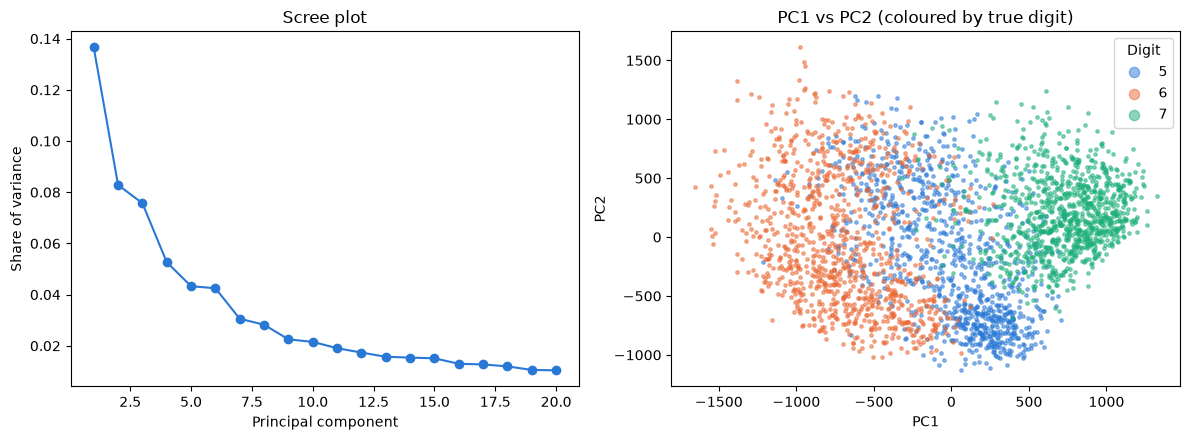

In [3]:
pca = PCA(n_components=20)
Z = pca.fit_transform(X)  # centred, not scaled (same as prcomp in R)

print(f"20 components keep {pca.explained_variance_ratio_.sum():.1%} of the pixel variance")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(range(1, 21), pca.explained_variance_ratio_, "o-", color="#2a78d6")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Share of variance")
for d, c in DIGIT_COLOURS.items():
    m = labels == d
    axes[1].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.5, color=c, label=str(d))
axes[1].set(title="PC1 vs PC2 (coloured by true digit)", xlabel="PC1", ylabel="PC2")
axes[1].legend(title="Digit", markerscale=3)
plt.tight_layout()

## 3. Clustering

Cluster numbers are arbitrary (cluster 0 is not necessarily the 5s), so before scoring each cluster is matched to a digit with the **Hungarian algorithm**: it picks the one-to-one matching that gets the most images right. The adjusted Rand index (ARI) gives a second, matching-free score.

In [4]:
def matched_accuracy(clusters, labels):
    """Accuracy after the best one-to-one matching of clusters to digits."""
    cm = pd.crosstab(labels, clusters).to_numpy()  # rows: digits, cols: clusters
    rows, cols = linear_sum_assignment(-cm)
    return cm[rows, cols].sum() / len(labels)

models = {
    "K-means": KMeans(n_clusters=3, n_init=25, random_state=1),
    "Single linkage": AgglomerativeClustering(n_clusters=3, linkage="single"),
    "Complete linkage": AgglomerativeClustering(n_clusters=3, linkage="complete"),
    "Average linkage": AgglomerativeClustering(n_clusters=3, linkage="average"),
    "Ward's linkage": AgglomerativeClustering(n_clusters=3, linkage="ward"),
}

clusters, rows = {}, []
for name, model in models.items():
    clusters[name] = model.fit_predict(Z)
    rows.append({"Method": name,
                 "Accuracy": matched_accuracy(clusters[name], labels),
                 "ARI": adjusted_rand_score(labels, clusters[name])})

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False)
results.style.format({"Accuracy": "{:.1%}", "ARI": "{:.3f}"}).hide(axis="index")

Method,Accuracy,ARI
Ward's linkage,98.2%,0.946
K-means,92.1%,0.780
Average linkage,66.1%,0.542
Complete linkage,55.8%,0.125
Single linkage,33.4%,-0.000


Ward's method minimises the variance inside each cluster, which suits PCA features (PCA is built around variance too). Single linkage "chains" nearly everything into one big cluster, so it scores no better than guessing.

In [5]:
ward = clusters["Ward's linkage"]
cm = pd.crosstab(labels, ward).to_numpy()
_, cols = linear_sum_assignment(-cm)
pd.DataFrame(cm[:, cols],
             index=[f"True {d}" for d in (5, 6, 7)],
             columns=[f"Cluster → {d}" for d in (5, 6, 7)])

,Cluster → 5,Cluster → 6,Cluster → 7
True 5,969,28,3
True 6,20,980,0
True 7,4,0,996


Most of the mistakes are 5s placed with the 6s: a 5 with a closed lower loop looks a lot like a 6.

## 4. Rebuilding images from a few components

PCA can be reversed: $\hat{X} = T_K U_K^\top + \mu$, using only the first $K$ scores $T_K$ and directions $U_K$.

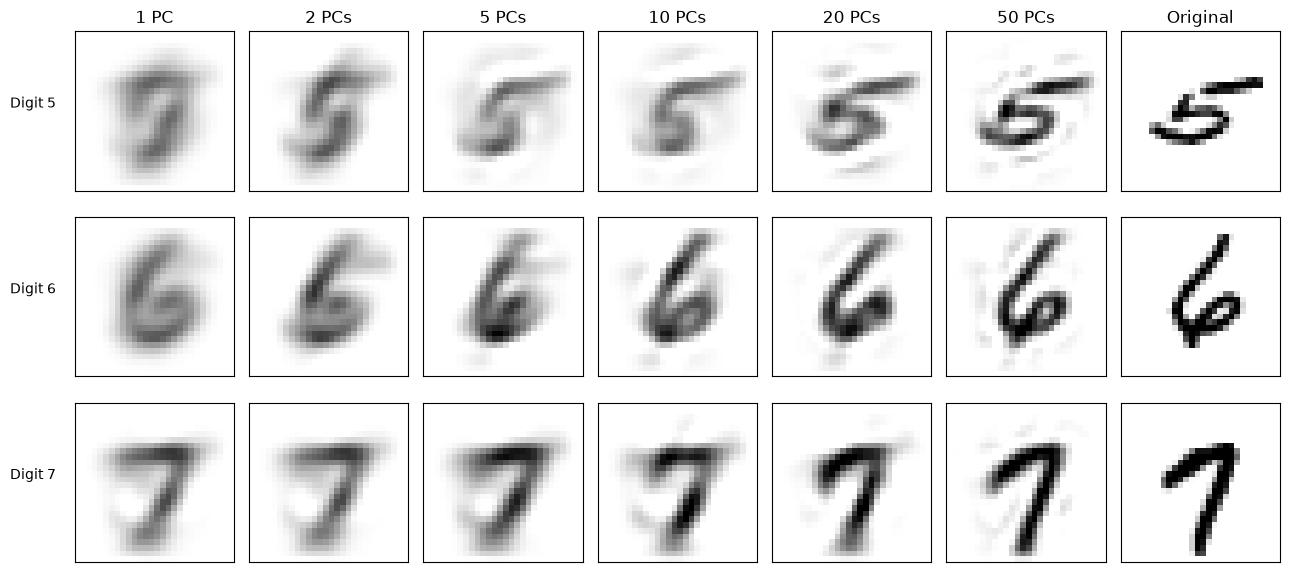

In [6]:
full = PCA().fit(X)
rng = np.random.default_rng(256)
examples = [rng.choice(np.flatnonzero(labels == d)) for d in (5, 6, 7)]
Ks = [1, 2, 5, 10, 20, 50]

def reconstruct(i, k):
    t = full.transform(X[i:i + 1])[:, :k]
    return (t @ full.components_[:k] + full.mean_).ravel()

fig, axes = plt.subplots(3, len(Ks) + 1, figsize=(13, 6))
for r, i in enumerate(examples):
    images = [reconstruct(i, k) for k in Ks] + [X[i]]
    titles = [f"{k} PC" + ("s" if k > 1 else "") for k in Ks] + ["Original"]
    for c, (img, title) in enumerate(zip(images, titles)):
        ax = axes[r, c]
        ax.imshow(img.reshape(28, 28), cmap="gray_r", vmin=0, vmax=X.max())
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(title)
    axes[r, 0].set_ylabel(f"Digit {labels[i]}", rotation=0, labelpad=30)
plt.tight_layout()

## Summary

- **PCA** shrinks each image from 784 numbers to 20 while keeping about two-thirds of the variance and the shape of each digit.
- **Ward's linkage** recovers the three digits best: about 98% of images land in the right group with no labels used. K-means comes second.
- **Reconstruction**: 10 to 20 components are enough to read the digit; 50 recover most of the detail.